Extracting derived variables (trip_duration, fare_amount, trip_distance, speed) from processed dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Correlation Matrix Summary ---
               trip_duration  fare_amount  trip_distance     speed
trip_duration       1.000000     0.092384       0.782291  0.226356
fare_amount         0.092384     1.000000       0.104990  0.063352
trip_distance       0.782291     0.104990       1.000000  0.688438
speed               0.226356     0.063352       0.688438  1.000000

Generating correlation matrix heatmap...


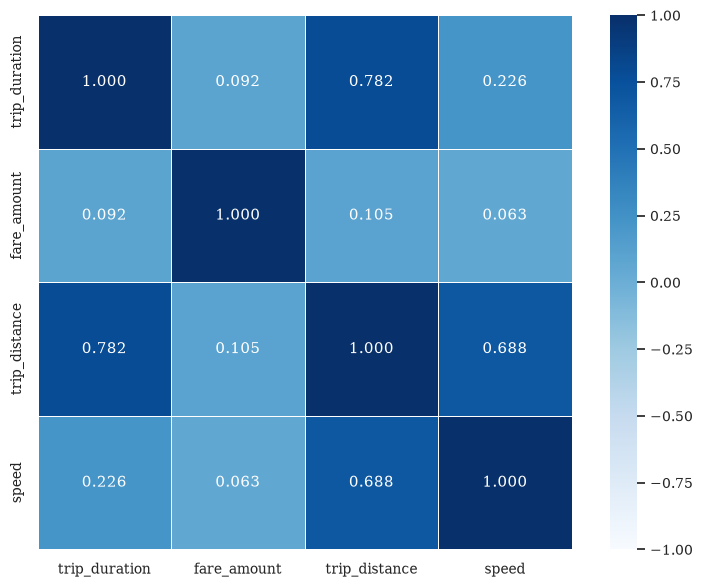

Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap.png'!


In [3]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory
con = duckdb.connect(database=':memory:')

print("Extracting derived variables (trip_duration, fare_amount, trip_distance, speed) from processed dataset...")

# 1. Query to derive trip_duration and speed on the fly without applying pre-filters
query = """
WITH derived AS (
    SELECT 
        trip_distance,
        fare_amount,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS speed
    FROM '../data/processed/*.parquet'
)
SELECT trip_duration, fare_amount, trip_distance, speed
FROM derived
"""

df_sample = con.execute(query).df()
con.close()

# 2. Compute the Pearson correlation matrix using Pandas
corr_matrix = df_sample[['trip_duration', 'fare_amount', 'trip_distance', 'speed']].corr()

print("\n--- Correlation Matrix Summary ---")
print(corr_matrix.to_string())

# 3. Generate a heatmap visualization for the correlation matrix
print("\nGenerating correlation matrix heatmap...")
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap="Blues", 
    cbar=True,
    square=True,
    linewidths=0.5,
    vmin=-1, 
    vmax=1
)

# plt.title('Correlation Matrix: Duration, Fare, Distance, and Speed')
plt.savefig('../reports/figures/correlation_matrix_heatmap.png', dpi=300)
plt.show()

print("Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap.png'!")

Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...
Loaded 50,000 sampled records. Generating pairwise scatter plot matrix...


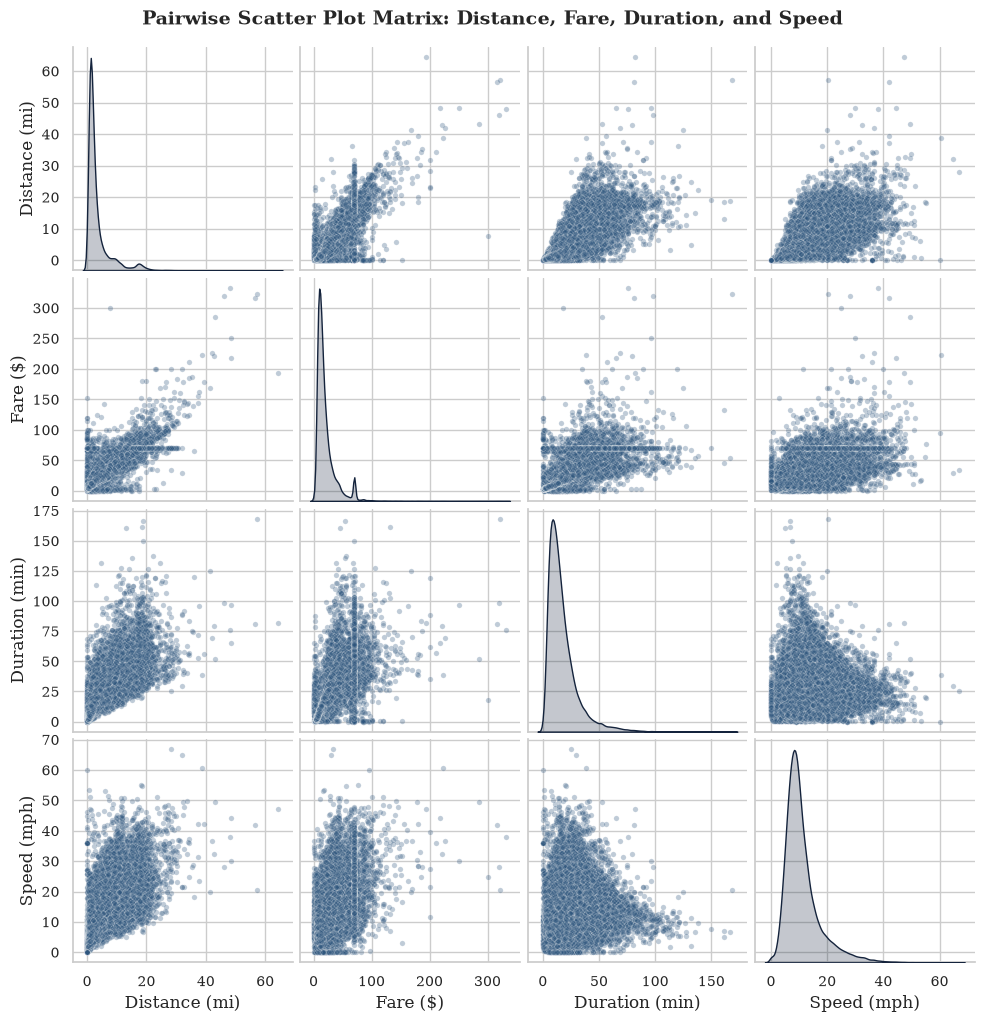

Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!


In [4]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory
con = duckdb.connect(database=':memory:')

print("Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...")

# Query to derive trip_duration and speed from processed parquet files
query = """
WITH derived AS (
    SELECT 
        trip_distance,
        fare_amount,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS speed
    FROM '../data/processed/*.parquet'
)
SELECT trip_distance, fare_amount, trip_duration, speed
FROM derived
USING SAMPLE 50000;
"""

df_sample = con.execute(query).df()
con.close()

print(f"Loaded {len(df_sample):,} sampled records. Generating pairwise scatter plot matrix...")

# Rename columns for clean plot labels
df_sample.columns = ['Distance (mi)', 'Fare ($)', 'Duration (min)', 'Speed (mph)']

# Generate pairplot (scatter plots for every pair, KDE on diagonal)
g = sns.pairplot(
    df_sample, 
    kind='scatter', 
    diag_kind='kde',
    plot_kws={'alpha': 0.3, 's': 15, 'color': '#2D557D'},
    diag_kws={'color': '#14233C', 'fill': True}
)

g.fig.suptitle('Pairwise Scatter Plot Matrix: Distance, Fare, Duration, and Speed', y=1.02, fontsize=14, fontweight='bold')

plt.savefig('../reports/figures/pairwise_scatter_matrix.png', dpi=300)
plt.show()

print("Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!")

In [1]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Querying micro-trip count and characteristics...")

micro_trip_query = """
WITH base AS (
    SELECT 
        tpep_pickup_datetime,
        tpep_dropoff_datetime,
        trip_distance,
        fare_amount,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS duration_min,
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS raw_speed_mph
    FROM '../data/raw/yellow_tripdata_2025-*.parquet'
)
SELECT 
    COUNT(*) AS total_micro_trips,
    AVG(trip_distance) AS avg_micro_distance,
    AVG(duration_min * 60.0) AS avg_duration_seconds,
    AVG(raw_speed_mph) AS avg_calculated_speed_mph
FROM base
WHERE duration_min > 0 
  AND duration_min < 1.0 
  AND trip_distance > 0;
"""

df_micro = con.execute(micro_trip_query).df()
con.close()

print("\n--- Micro-Trip Summary Statistics ---")
print(df_micro.to_string(index=False))

Querying micro-trip count and characteristics...

--- Micro-Trip Summary Statistics ---
 total_micro_trips  avg_micro_distance  avg_duration_seconds  avg_calculated_speed_mph
            177299            0.265399             23.799367                 96.925412


In [2]:
import duckdb
import glob

print("Searching for available files:")
print(glob.glob("../data/raw/*.parquet"))
print(glob.glob("../data/processed/*.parquet"))

con = duckdb.connect(database=':memory:')

query = """
SELECT 
    COUNT(*) AS total_micro_trips_gt_80
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0
    AND EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 < 1.0
    AND trip_distance > 0
    AND (trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)) > 80;
"""

try:
    res = con.execute(query).fetchone()
    print(f"Result: {res[0]}")
except Exception as e:
    print(f"Error: {e}")

con.close()

Searching for available files:
['../data/raw\\yellow_tripdata_2025-01.parquet', '../data/raw\\yellow_tripdata_2025-02.parquet', '../data/raw\\yellow_tripdata_2025-03.parquet', '../data/raw\\yellow_tripdata_2025-04.parquet', '../data/raw\\yellow_tripdata_2025-05.parquet', '../data/raw\\yellow_tripdata_2025-06.parquet', '../data/raw\\yellow_tripdata_2025-07.parquet', '../data/raw\\yellow_tripdata_2025-08.parquet', '../data/raw\\yellow_tripdata_2025-09.parquet', '../data/raw\\yellow_tripdata_2025-10.parquet', '../data/raw\\yellow_tripdata_2025-11.parquet', '../data/raw\\yellow_tripdata_2025-12.parquet']
['../data/processed\\yellow_tripdata_2025_clean.parquet']
Result: 8063
